In [1]:
#Basic Preprocessing

import os
import cv2
import numpy as np
from tqdm import tqdm


def preprocess_image(image_path, img_size=(256, 256)):
 
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    img_resized = cv2.resize(img, img_size)
    img_normalized = img_resized / 255.0

    return img_normalized


input_folder = r"F:\Without Report-20250505T191518Z-001\Without Report\all wr"
output_folder = r"F:\Without Report-20250505T191518Z-001\Without Report\prepo"


os.makedirs(output_folder, exist_ok=True)


for filename in tqdm(os.listdir(input_folder)):
    if filename.endswith(".bmp") or filename.endswith(".jpg"):
        image_path = os.path.join(input_folder, filename)
        preprocessed_image = preprocess_image(image_path)
        output_path = os.path.join(output_folder, filename)
        cv2.imwrite(output_path, (preprocessed_image * 255).astype(np.uint8))

print("Preprocessing completed!")

100%|██████████| 6564/6564 [01:24<00:00, 77.76it/s] 

Preprocessing completed!


In [ ]:
#Noise Analysis

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter


hdct_dir = r"F:\Without Report-20250505T191518Z-001\Without Report\prepo"
output_dir = r"F:\Without Report-20250505T191518Z-001\Without Report\noise"

os.makedirs(output_dir, exist_ok=True)

def noise_analysis(image_path):
    
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    denoised_img = gaussian_filter(img, sigma=1)
    noise = img - denoised_img  # High frequency residual map. Contains some real noise, some edges, some anatomical detail, some reconstruction artifacts.
    
    
    noise_normalized = cv2.normalize(noise, None, 0, 255, cv2.NORM_MINMAX)
    
    return img, denoised_img, noise_normalized


for filename in os.listdir(hdct_dir):
    if filename.endswith('.png') or filename.endswith('.jpg') or filename.endswith('.bmp'):
        image_path = os.path.join(hdct_dir, filename)
        
      
        img, denoised_img, noise_normalized = noise_analysis(image_path)
        
       
        output_noise_path = os.path.join(output_dir, f'noise_{filename}')
        cv2.imwrite(output_noise_path, noise_normalized)

     
        #plt.figure(figsize=(15, 5))
        #plt.subplot(1, 3, 1)
        #plt.title('Original Image')
        #plt.imshow(img, cmap='gray')
        #plt.subplot(1, 3, 2)
        #plt.title('Denoised Image')
        #plt.imshow(denoised_img, cmap='gray')
        #plt.subplot(1, 3, 3)
        #plt.title('Noise Image')
        #plt.imshow(noise_normalized, cmap='gray')
        #plt.show()



In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models


# The model will learn how to compress and construct residual patterns i.e. high frequency residual maps
def build_autoencoder(input_shape=(256, 256, 1), latent_dim=256):
    input_img = layers.Input(shape=input_shape) 

    # Encoder        
    # Learns compact representation of residual textures                                                          # dimension*dimension*no_of_feature_maps
    x = layers.Conv2D(32, (3, 3), activation='relu', strides=2, padding='same')(input_img)   # 128*128*32
    x = layers.Conv2D(64, (3, 3), activation='relu', strides=2, padding='same')(x)    # 64*64*64
    x = layers.Conv2D(128, (3, 3), activation='relu', strides=2, padding='same')(x)    # 32*32*128
    x = layers.Flatten()(x)    # 32*32*128=131072
    latent = layers.Dense(latent_dim, activation='relu')(x)     # 131072 features get connected to 256 neurons in hidden layer 1

    # Decoder
    # Learns how to reconstruct the residual textures back to images
    x = layers.Dense(32 * 32 * 128, activation='relu')(latent)      # output of 256 neurons get connected to 131072 neurons in hidden layer 2 
    x = layers.Reshape((32, 32, 128))(x)    # 131072 → 32×32×128 (Latent becomes small "image-like" tensor. Creates spatial structure again)
    # Upsampling phase
    x = layers.Conv2DTranspose(128, (3, 3), activation='relu', strides=2, padding='same')(x)  # 32×32x128 → 64×64x128
    x = layers.Conv2DTranspose(64, (3, 3), activation='relu', strides=2, padding='same')(x)    # 64×64×128 → 128×128×64
    x = layers.Conv2DTranspose(32, (3, 3), activation='relu', strides=2, padding='same')(x)  # 128×128×64 → 256×256×32
    output_img = layers.Conv2DTranspose(1, (3, 3), activation='sigmoid', padding='same')(x)  # 256×256×32 → 256×256×1

    
    autoencoder = models.Model(input_img, output_img)
    autoencoder.compile(optimizer='adam', loss='mse')  # MSE = (original - reconstructed)^2

    return autoencoder

In [ ]:
from tensorflow.keras.preprocessing import image


def load_images(image_folder, img_size=(256, 256)):
    images = []
    for img_name in os.listdir(image_folder):
        img_path = os.path.join(image_folder, img_name)
        img = image.load_img(img_path, target_size=img_size, color_mode='grayscale') 
        img = image.img_to_array(img) / 255.0  # Normalize to [0, 1]
        images.append(img)
    return np.array(images)


image_folder = r"F:\Without Report-20250505T191518Z-001\Without Report\noise"
images = load_images(image_folder)


autoencoder = build_autoencoder()
autoencoder.fit(images, images, epochs=50, batch_size=8)


autoencoder.save('noise_autoencoder.h5')

Epoch 1/50
821/821 [==============================] - 963s 1s/step - loss: 0.0843
Epoch 2/50
821/821 [==============================] - 967s 1s/step - loss: 0.0650
Epoch 3/50
821/821 [==============================] - 969s 1s/step - loss: 0.0600
Epoch 4/50
821/821 [==============================] - 960s 1s/step - loss: 0.0575
Epoch 5/50
821/821 [==============================] - 1058s 1s/step - loss: 0.0559
Epoch 6/50
821/821 [==============================] - 1009s 1s/step - loss: 0.0548
Epoch 7/50
821/821 [==============================] - 1028s 1s/step - loss: 0.0538
Epoch 8/50
821/821 [==============================] - 1000s 1s/step - loss: 0.0531
Epoch 9/50
821/821 [==============================] - 1004s 1s/step - loss: 0.0525
Epoch 10/50
821/821 [==============================] - 952s 1s/step - loss: 0.0519
Epoch 11/50
821/821 [==============================] - 927s 1s/step - loss: 0.0515
Epoch 12/50
821/821 [==============================] - 928s 1s/step - loss: 0.0511
Epoch 13

In [ ]:
encoder = models.Model(autoencoder.input, autoencoder.get_layer('dense').output)  # Extract encoder part
encoded_images = encoder.predict(images)  # output is the compressed vector (latent space) i.e. 256 numbers instead of 256×256 pixels
# Latent space is a compressed mathematical representation of data (Coordinates of an image in a feature space)

206/206 [==============================] - 15s 70ms/step


In [ ]:
# Perturbation
def generate_synthetic_noise(encoded_images, noise_factor=2, poisson_lambda=1.0):
    # Apply Gaussian noise
    gaussian_noise = np.random.normal(loc=0.0, scale=noise_factor, size=encoded_images.shape)
    
    # Apply Poisson noise
    poisson_noise = np.random.poisson(lam=poisson_lambda, size=encoded_images.shape)
    
    # Add both Gaussian and Poisson noise to the original encoded image
    synthetic_noise = encoded_images + gaussian_noise + poisson_noise
    
    return synthetic_noise


1/1 [==============================] - 0s 270ms/step


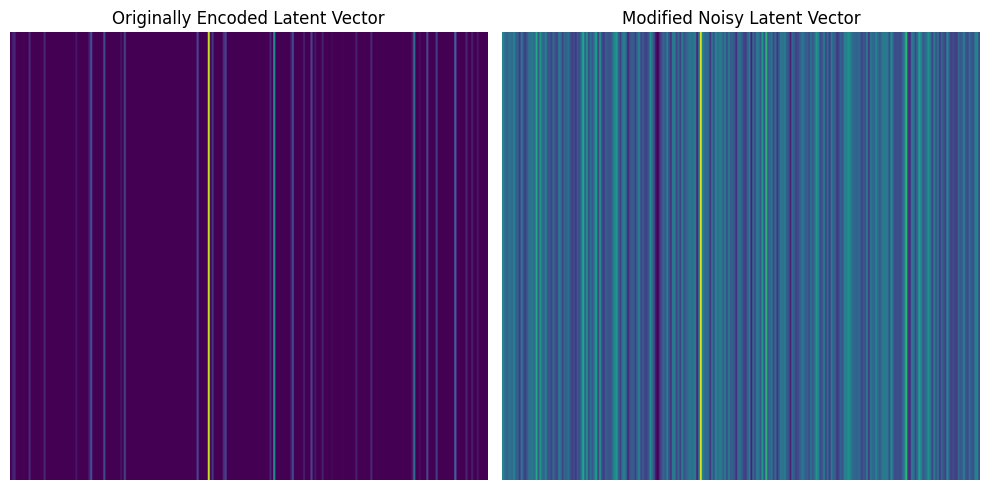

In [7]:
latent_dim = encoded_images.shape[1]
decoder_input = layers.Input(shape=(latent_dim,))
x = layers.Dense(32 * 32 * 128, activation='relu')(decoder_input)
x = layers.Reshape((32, 32, 128))(x)
x = layers.Conv2DTranspose(128, (3, 3), activation='relu', strides=2, padding='same')(x)
x = layers.Conv2DTranspose(64, (3, 3), activation='relu', strides=2, padding='same')(x)
x = layers.Conv2DTranspose(32, (3, 3), activation='relu', strides=2, padding='same')(x)
output_img = layers.Conv2DTranspose(1, (3, 3), activation='sigmoid', padding='same')(x)

decoder = models.Model(decoder_input, output_img)
synthetic_noisy_images = decoder.predict(generate_synthetic_noise(encoded_images))
noisy_encoded_image = generate_synthetic_noise(encoded_images[0:1])  # Shape (1, latent_dim)

encoded_image = encoded_images[0:1]  # Shape (1, latent_dim)

# Generate synthetic noise for the first encoded image (Gaussian + Poisson)
noisy_encoded_image = generate_synthetic_noise(encoded_image)  # Shape (1, latent_dim)

# Decode the noisy latent vector to get the synthetic noisy image
synthetic_noisy_image = decoder.predict(noisy_encoded_image)

# Plot the encoded image (latent vector) and synthetic noisy latent vector
plt.figure(figsize=(10, 5))

# Plot the encoded image (latent representation)
plt.subplot(1, 2, 1)
plt.imshow(encoded_image[0].reshape(1, -1), cmap='viridis', aspect='auto')  # Reshaped for better visualization
plt.title("Originally Encoded Latent Vector")
plt.axis('off')

# Plot the synthetic noisy image as a latent vector
# Here we treat the latent vector of the synthetic noisy image like the original encoded vector
synthetic_noisy_latent_vector = noisy_encoded_image[0]  # This is the latent space representation of the noisy image

plt.subplot(1, 2, 2)
plt.imshow(synthetic_noisy_latent_vector.reshape(1, -1), cmap='viridis', aspect='auto')  # Reshaped for better visualization
plt.title("Modified Noisy Latent Vector")
plt.axis('off')

# Show the plots
plt.tight_layout()
plt.show()

In [1]:
import numpy as np
from skimage.metrics import structural_similarity as ssim

def apply_noise_to_ct(ct_images, synthetic_noisy_images, noise_factor=0.5, poisson_noise=True):
    # Get the number of images in the dataset
    num_images = ct_images.shape[0]
    
    # Generate random indices to select random synthetic noisy images
    random_indices = np.random.randint(0, synthetic_noisy_images.shape[0], size=num_images)
    
    # Select random synthetic noisy images for each CT image
    selected_synthetic_noisy_images = synthetic_noisy_images[random_indices]
    
    # Apply the noise by adding the selected noisy images scaled by noise_factor
    noisy_ct_images = ct_images + noise_factor * selected_synthetic_noisy_images
    
    # Clip the values to keep them within the valid range [0, 1]
    noisy_ct_images = np.clip(noisy_ct_images, 0, 1)
    
    # Optionally apply Poisson noise
    if poisson_noise:
        noisy_ct_images = np.random.poisson(noisy_ct_images * 255) / 255.0
    
    return noisy_ct_images



# Example usage
ct_images = np.random.rand(10, 256, 256)  # Example CT images (10 images of size 256x256)
synthetic_noisy_images = np.random.rand(10, 256, 256)  # Example synthetic noisy images

noisy_ct_images = apply_noise_to_ct(ct_images, synthetic_noisy_images)




206/206 [==============================] - 108s 525ms/step
All noisy images saved to F:\Without Report-20250505T191518Z-001\Without Report\all noisy wr

Comparison:


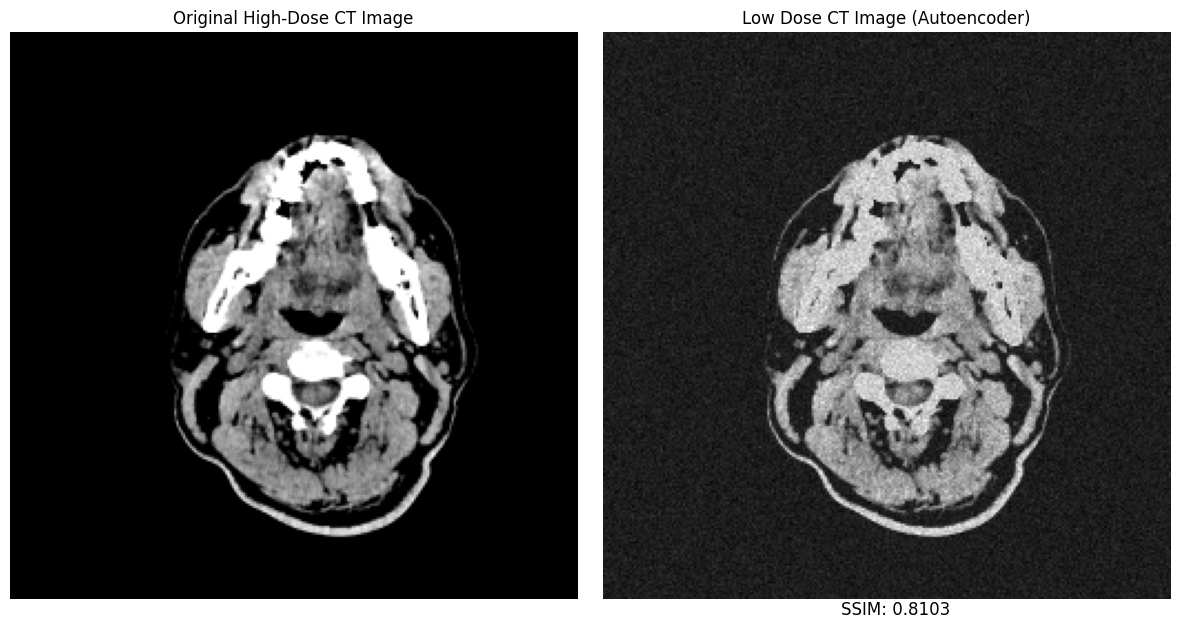

In [ ]:
import os
import imageio
import numpy as np
import matplotlib.pyplot as plt

# Define folder paths
high_dose_ct_folder = r"F:\Without Report-20250505T191518Z-001\Without Report\prepo"
output_folder = r"F:\Without Report-20250505T191518Z-001\Without Report\all noisy wr"

# Create output folder if it doesn't exist
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# Load high-dose CT images
high_dose_filenames = sorted(os.listdir(high_dose_ct_folder))
ct_images = load_images(high_dose_ct_folder)

# Generate synthetic noisy images
synthetic_noisy_images = decoder.predict(generate_synthetic_noise(encoded_images))
noisy_ct_images = apply_noise_to_ct(ct_images, synthetic_noisy_images)

# Normalize and convert to uint8
noisy_ct_images = np.squeeze(noisy_ct_images)
noisy_ct_images = (noisy_ct_images / np.max(noisy_ct_images) * 255).astype(np.uint8)

# Save images with the same filenames as high-dose images
for i, filename in enumerate(high_dose_filenames):
    noisy_ct_rgb = np.stack((noisy_ct_images[i],) * 3, axis=-1)  # Convert grayscale to RGB
    noisy_image_path = os.path.join(output_folder, filename)  # Preserve original filename
    imageio.imwrite(noisy_image_path, noisy_ct_rgb)

# Display comparison
ssim_value = 0.8103  # Example SSIM value
print(f"All noisy images saved to {output_folder}\n")

print('Comparison:')
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(ct_images[0], cmap='gray')
axes[0].set_title("Original High-Dose CT Image")
axes[0].axis('off')

axes[1].imshow(noisy_ct_images[0], cmap='gray')
axes[1].set_title("Low Dose CT Image (Autoencoder)")
plt.figtext(0.8, 0.0001, f"SSIM: {ssim_value:.4f}", ha="right", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()


